# AC Final — Aprendizado por Reforço: Pong com PPO
**Aluno:** Joao Pedro Castro · **Professor:** Pedro Calais

Notebook adaptado do [código da galinha / Freeway fornecido pelo professor](https://drive.google.com/file/d/10liyDw_oMNjvP2N9g0IFz6nhaKWtpZc5/view).
Usamos a mesma biblioteca **Stable Baselines 3**, algoritmo **PPO**, política **CnnPolicy**, pré-processamento **AtariWrapper**, Monitor, TensorBoard e gravação de vídeo.
O link acima aponta para o código de referência.

## Roteiro e honestidade dos resultados
Execute as células em ordem com o kernel `.venv/bin/python` no VS Code. O treinamento pode demorar horas e pode exigir ampliar o orçamento. Não há garantia de convergência.
As saídas são medidas na execução; campos pessoais e análise do vídeo ficam explicitamente pendentes até serem preenchidos.
Não use `Run All` para jogar: a sessão humana é uma etapa interativa separada.


## 1. Jogo, ambiente, ações e recompensas
**Escolha: Pong**, presente na [lista oficial de Atari](https://ale.farama.org/environments/complete_list/) e com [página própria](https://ale.farama.org/environments/pong/).
O agente controla a raquete da direita e enfrenta a raquete da esquerda, controlada pelo computador. Deve devolver a bola e fazê-la ultrapassar o adversário.
A observação RGB original tem formato **210 × 160 × 3**, valores inteiros de 0 a 255. A rede recebe quatro imagens consecutivas em cinza de **84 × 84**, para inferir movimento.

O conjunto reduzido padrão (`full_action_space=False`) possui **6 ações**:

| Índice | Nome ALE | Efeito no Pong |
|---|---|---|
| 0 | NOOP | Sem comando de movimento |
| 1 | FIRE | Botão de ação |
| 2 | RIGHT | Move a raquete para cima |
| 3 | LEFT | Move a raquete para baixo |
| 4 | RIGHTFIRE | Para cima + botão |
| 5 | LEFTFIRE | Para baixo + botão |

Os nomes RIGHT/LEFT são do controle Atari; em Pong correspondem ao movimento vertical da raquete.
**Recompensa:** +1 ao marcar um ponto; −1 ao sofrer um ponto; 0 nos demais frames. Rebater a bola por si só não dá recompensa.
Uma partida termina quando um dos jogadores chega a 21 pontos; tratamos também o sinal `truncated` do ambiente.

**Configuração escolhida:** `ALE/Pong-v5`, mas com `frameskip=1` na base e `frame_skip=4` no wrapper (total 4, evitando 4 × 4). Mantemos a probabilidade de ações persistentes do v5 (`repeat_action_probability=0.25`).
Desativamos episódios artificiais por perda de vida e clipping para medir partidas e retornos reais, igualmente no treino e na avaliação.
O tempo de um vídeo corresponde aos frames do emulador capturados a 60 fps, não ao tempo de processamento do computador.


## 2. Preparação no VS Code
Abra esta pasta no VS Code. Instale as extensões **Python** (`ms-python.python`) e **Jupyter** (`ms-toolsai.jupyter`).
Em **Select Kernel → Python Environments**, selecione `.venv/bin/python`.

Para recriar o ambiente (Python 3.11 ou 3.12):
```sh
python3.12 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt
```
A distribuição atual do ALE inclui ROMs; não repetimos a instalação antiga via AutoROM do notebook base.


In [1]:
from pathlib import Path
import sys, json, time, platform, importlib.metadata as metadata
import numpy as np
import gymnasium as gym
import ale_py
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.atari_wrappers import AtariWrapper
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv, VecFrameStack, VecTransposeImage
from stable_baselines3.common.callbacks import BaseCallback, CheckpointCallback
from stable_baselines3.common.evaluation import evaluate_policy
from IPython.display import display, Video, Markdown
import imageio.v2 as imageio

gym.register_envs(ale_py)
ROOT = Path.cwd().resolve()
assert (ROOT / 'requirements.txt').exists(), 'Abra o notebook com a pasta pong-rl como diretório atual.'
for name in ['artifacts', 'videos', 'models', 'logs', 'evidence']:
    (ROOT / name).mkdir(exist_ok=True)
torch.set_num_threads(4)
versions = {p: metadata.version(p) for p in ['stable-baselines3','gymnasium','ale-py','torch','tensorboard']}
versions.update(python=sys.version, platform=platform.platform(), device='cpu')
(ROOT/'artifacts/versions.json').write_text(json.dumps(versions, indent=2))
print(json.dumps(versions, indent=2))


{
  "stable-baselines3": "2.9.2",
  "gymnasium": "1.4.0",
  "ale-py": "0.11.2",
  "torch": "2.15.0",
  "tensorboard": "2.21.0",
  "python": "3.12.16 (main, Oct 26 2026, 13:59:40) [Clang 23.1.3 ]",
  "platform": "macOS-26.6-arm64-arm-64bit",
  "device": "cpu"
}


In [2]:
SEED = 42
ENV_ID = 'ALE/Pong-v5'
N_ENVS = 8
TOTAL_TIMESTEPS = 2_000_000  # orçamento inicial; ampliar se o critério não for atingido
EVAL_EVERY = 50_000
N_EVAL_EPISODES = 5
# Critério operacional declarado ANTES de treinar: média >= -5 em 5 partidas.
# É um indicador de progresso, não uma prova estatística de domínio do jogo.
INTELLIGENT_THRESHOLD = -5.0
PPO_PARAMS = dict(n_steps=128, batch_size=256, learning_rate=2.5e-4,
                  n_epochs=4, ent_coef=0.01, clip_range=0.1,
                  gamma=0.99, gae_lambda=0.95)
config = dict(env_id=ENV_ID, seed=SEED, n_envs=N_ENVS, total_timesteps=TOTAL_TIMESTEPS,
              threshold=INTELLIGENT_THRESHOLD, eval_episodes=N_EVAL_EPISODES,
              frameskip_base=1, frame_skip_wrapper=4, sticky_probability=0.25,
              frame_stack=4, **PPO_PARAMS)
(ROOT/'artifacts/config.json').write_text(json.dumps(config, indent=2))


395

## 3. Verificação do ambiente e experiência humana
A célula seguinte consulta as ações e as recompensas efetivamente expostas pela instalação.
Para cumprir **“jogue você mesmo”**, execute no terminal integrado:
```sh
.venv/bin/python jogar.py
```
Use **W / seta para cima**, **S / seta para baixo**, **espaço** para o botão e **Esc** para encerrar. A janela precisa estar em foco.
### Relato pessoal

Para me familiarizar com o ambiente, criamos o arquivo `jogar.py`, que permite jogar Pong manualmente usando as setas do teclado para mover a raquete para cima e para baixo. Nessa experiência, controlei a raquete da direita e enfrentei o adversário automático do Atari, que controla a raquete da esquerda.

O objetivo é rebater a bola, impedir que ela ultrapasse a própria raquete e fazê-la passar pela raquete adversária para marcar pontos. Durante minha experiência, perdi e achei o jogo muito difícil. A partida me ajudou a perceber que uma regra simples pode exigir bastante habilidade para ser executada.

Essa familiarização também ajudou a compreender o desafio do agente de aprendizado por reforço: ele precisa usar as imagens do jogo para aprender quando movimentar a raquete e como se posicionar para devolver a bola. Diferentemente de receber uma instrução pronta para cada situação, o agente aprende por meio das recompensas obtidas ao marcar pontos e das penalidades ao sofrer pontos.

**Registro da sessão:** o arquivo `artifacts/sessao_humana.json` registra 40,51 segundos e saldo parcial de −9. Essa gravação da sessão foi encerrada sem uma partida completa registrada; o relato acima reproduz a experiência informada pelo aluno.


In [3]:
raw = gym.make(ENV_ID, frameskip=1, repeat_action_probability=0.25, full_action_space=False)
obs, _ = raw.reset(seed=SEED)
print('Observação:', obs.shape, obs.dtype)
print('Ações:', raw.action_space, raw.unwrapped.get_action_meanings())
assert raw.action_space.n == 6 and obs.shape == (210, 160, 3)
raw.close()


Observação: (210, 160, 3) uint8
Ações: Discrete(6) ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']


A.L.E: Arcade Learning Environment (version 0.11.2+ecc1138)
[Powered by Stella]


## 4. Função de ambiente comum
Monitor registra retorno por partida. AtariWrapper reduz imagens e repete ações quatro vezes.
VecFrameStack mantém quatro observações; VecTransposeImage fornece a disposição de canais esperada pelo PyTorch.
O mesmo pré-processamento é usado na política aleatória, treino, avaliação e vídeo final.


In [4]:
class StreamingVideo(gym.Wrapper):
    """Grava uma partida em streaming, sem acumular frames em RAM."""
    def __init__(self, env, path):
        super().__init__(env)
        path.parent.mkdir(parents=True,exist_ok=True)
        self.writer=imageio.get_writer(str(path.with_suffix('.mp4')),fps=60,
                                     codec='libx264',macro_block_size=1)
        self.frame_count=0
    def _frame(self):
        if self.writer is not None:
            self.writer.append_data(self.env.render()); self.frame_count+=1
    def reset(self, **kwargs):
        result=self.env.reset(**kwargs); self._frame(); return result
    def step(self, action):
        result=self.env.step(action); self._frame()
        if result[2] or result[3]: self._finish()
        return result
    def _finish(self):
        if self.writer is not None: self.writer.close(); self.writer=None
    def close(self):
        self._finish(); return self.env.close()

def make_single(seed, monitor_path=None, capture_path=None):
    env = gym.make(ENV_ID, frameskip=1, repeat_action_probability=0.25,
                   full_action_space=False, render_mode='rgb_array')
    # Captura ANTES do wrapper: preserva 60 frames/s e todos os frames repetidos.
    if capture_path is not None:
        env = StreamingVideo(env, capture_path)
    env = Monitor(env, filename=str(monitor_path) if monitor_path else None)
    env = AtariWrapper(env, frame_skip=4, terminal_on_life_loss=False, clip_reward=False)
    env.action_space.seed(seed)
    return env

def make_vec(n=1, seed=SEED, monitor_dir=None, capture_path=None):
    factories=[]
    for i in range(n):
        path = monitor_dir/f'env_{i}' if monitor_dir else None
        factories.append(lambda i=i, path=path: make_single(seed+i, path, capture_path))
    env = VecTransposeImage(VecFrameStack(DummyVecEnv(factories), n_stack=4))
    env.seed(seed)
    return env

class RandomPolicy:
    def __init__(self, seed): self.rng=np.random.default_rng(seed)
    def predict(self, observation, state=None, episode_start=None, deterministic=False):
        return self.rng.integers(0, 6, size=observation.shape[0]), state

def evaluate_random(episodes=5):
    env=make_vec(seed=1000)
    try:
        returns, lengths = evaluate_policy(RandomPolicy(SEED), env,
            n_eval_episodes=episodes, return_episode_rewards=True, warn=False)
        result=dict(returns=returns, lengths=lengths, mean=float(np.mean(returns)),
                    std=float(np.std(returns)), episodes=episodes, seed=1000)
        (ROOT/'artifacts/random_evaluation.json').write_text(json.dumps(result, indent=2))
        return result
    finally: env.close()

def record_episode(policy, label, seed=2026):
    folder=ROOT/'videos'/label
    folder.mkdir(exist_ok=True)
    # Pasta nova por execução, evitando misturar vídeos de políticas distintas.
    run_folder=folder/time.strftime('%Y%m%d_%H%M%S')
    env=make_vec(seed=seed, capture_path=run_folder/label)
    events=[]; ret=0.0; steps=0; completed=False
    try:
        obs=env.reset()
        for steps in range(1, 30_001):
            action,_=policy.predict(obs, deterministic=True)
            obs,rewards,dones,infos=env.step(action)
            ret+=float(rewards[0])
            if rewards[0]: events.append(dict(decision=steps, reward=float(rewards[0]), return_so_far=ret))
            if dones[0]:
                completed=True
                break
    finally: env.close()
    # VecEnv reinicia automaticamente após done; selecionamos a primeira partida.
    video=sorted(run_folder.glob('*.mp4'))[0]
    result=dict(video=str(video.relative_to(ROOT)), return_=ret, decisions=steps,
                completed=completed, seed=seed, events=events)
    (ROOT/f'artifacts/{label}_video.json').write_text(json.dumps(result, indent=2))
    return video, result


## 5. Política aleatória, sem aprendizado
Cada ação é sorteada uniformemente entre as seis disponíveis, independentemente da imagem. Não há rede treinada nesta etapa.
Avaliamos cinco partidas e gravamos uma partida separada. A avaliação final utiliza dez partidas com seeds diferentes dos checkpoints periódicos. O baseline utiliza cinco partidas; a comparação é descritiva e não constitui um teste estatístico pareado.


In [5]:
random_result = evaluate_random()
print(random_result)
random_video, random_video_info = record_episode(RandomPolicy(123), 'aleatorio')
display(Video(str(random_video), embed=True))


{'returns': [-21.0, -21.0, -20.0, -20.0, -20.0], 'lengths': [3558, 3796, 3535, 3689, 5295], 'mean': -20.4, 'std': 0.4898979485566356, 'episodes': 5, 'seed': 1000}


## 6. O que mudou em relação à galinha
Os valores de Freeway foram lidos diretamente do notebook fornecido, não presumidos.

| Item | Código base Freeway | Pong deste notebook | Motivo |
|---|---|---|---|
| Ambiente | ALE/Freeway-v5 | ALE/Pong-v5 | Jogo escolhido |
| Algoritmo / política | PPO / CnnPolicy | Mantidos | Preservar a base exigida |
| n_steps | 2048 | 128 por ambiente | Rollouts menores com 8 ambientes (1024 transições/atualização) |
| Ambientes | 1 | 8 | Diversificar experiências por atualização; DummyVecEnv executa sequencialmente |
| batch_size | 256 | 256 | Mantido |
| learning_rate | 2.5e-4 | 2.5e-4 | Mantido |
| n_epochs | padrão PPO: 10 | 4 | Menor reutilização de cada rollout |
| ent_coef | padrão PPO: 0 | 0.01 | Incentivar exploração |
| clip_range | padrão PPO: 0.2 | 0.1 | Atualizações mais conservadoras |
| gamma / gae_lambda | padrões: 0.99 / 0.95 | Mantidos | Crédito temporal |
| total_timesteps | 50.000 | 2.000.000 inicialmente | Orçamento experimental maior, sem prometer convergência |
| Frameskip | base padrão 4 + wrapper 4 | base 1 + wrapper 4 | Evitar repetição dupla |
| Histórico visual | 1 imagem | 4 imagens | Inferir direção e velocidade da bola |
| Monitor / avaliação | Monitor; vídeo final | Monitor + avaliação periódica + baseline | Medir progresso e tempo até o critério |
| TensorBoard | freeway_tensorboard | logs/tensorboard | Separar os experimentos |

Os ajustes de PPO se inspiram no [preset Atari do RL Baselines3 Zoo](https://github.com/DLR-RM/rl-baselines3-zoo/blob/master/hyperparams/ppo.yml).
Não são uma cópia exata: usamos orçamento inicial menor, taxa/clip constantes e mantemos ações persistentes do v5.
[AtariWrapper](https://stable-baselines3.readthedocs.io/en/master/common/atari_wrappers.html) · [PPO](https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html).
**Ajustes adicionais durante esta execução:** não houve alteração de hiperparâmetros durante o treinamento; a tabela registra a configuração efetivamente usada.


In [6]:
train_env = make_vec(N_ENVS, SEED, ROOT/'logs')
model = PPO('CnnPolicy', train_env, verbose=1, seed=SEED, device='cpu',
            tensorboard_log=str(ROOT/'logs/tensorboard'), **PPO_PARAMS)
counts = [{'camada': name, 'formato': list(p.shape), 'parametros': p.numel(),
           'treinavel': p.requires_grad} for name,p in model.policy.named_parameters()]
parameter_count = sum(p.numel() for p in model.policy.parameters())
trainable_count = sum(p.numel() for p in model.policy.parameters() if p.requires_grad)
(ROOT/'artifacts/network.json').write_text(json.dumps(dict(total=parameter_count,
    trainable=trainable_count, layers=counts, architecture=str(model.policy)), indent=2))
print(model.policy)
print(f'Parâmetros totais: {parameter_count:,}; treináveis: {trainable_count:,}')


Using cpu device


ActorCriticCnnPolicy(
  (features_extractor): NatureCNN(
    (cnn): Sequential(
      (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
      (1): ReLU()
      (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
      (3): ReLU()
      (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
      (5): ReLU()
      (6): Flatten(start_dim=1, end_dim=-1)
    )
    (linear): Sequential(
      (0): Linear(in_features=3136, out_features=512, bias=True)
      (1): ReLU()
    )
  )
  (pi_features_extractor): NatureCNN(
    (cnn): Sequential(
      (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
      (1): ReLU()
      (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
      (3): ReLU()
      (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
      (5): ReLU()
      (6): Flatten(start_dim=1, end_dim=-1)
    )
    (linear): Sequential(
      (0): Linear(in_features=3136, out_features=512, bias=True)
      (1): ReLU()
    )
  )
  (vf_features_extractor): NatureCNN(
    (cnn): 

## 7. Avaliação, tempo de aprendizado e treinamento
A cada aproximadamente 50 mil transições agregadas dos oito ambientes, avaliamos **cinco partidas completas**, com política determinística e seeds fixos.
**Política minimamente inteligente:** primeiro checkpoint com retorno médio ≥ −5. Esse limiar representa uma definição operacional escolhida para este trabalho; confirme também visualmente o comportamento.
Registramos tempo de treino **incluindo avaliações** e número de transições. A avaliação final usa seeds diferentes para reduzir o viés de selecionar pelo conjunto periódico.
Se o limiar não for alcançado, a resposta será **“não atingido neste orçamento”**, com o tempo e desempenho observados.

### Resultado medido — itens i e j

O primeiro checkpoint que atingiu o critério foi o de **550.000 passos**, com retorno médio **−2,2** em cinco partidas, após **1.481,50 segundos (24min42s)**, incluindo as avaliações. Isso representa o primeiro alcance do limiar, e não estabilidade definitiva: houve oscilações posteriores. O treino completo executou **2.000.896 transições** em **5.213,93 segundos (1h26min54s)**; o pequeno excedente ocorre porque PPO completa o rollout.

A rede treinada tem **1.687.719 parâmetros**, todos treináveis, contados diretamente com `sum(p.numel() for p in model.policy.parameters())`. A arquitetura e as contagens por camada estão na saída abaixo e em `artifacts/network.json`.


In [7]:
from contextlib import redirect_stdout, redirect_stderr

class ProgressCallback(BaseCallback):
    def __init__(self, frequency=EVAL_EVERY):
        super().__init__(); self.frequency=frequency; self.next_eval=frequency
        self.history=[]; self.first=None; self.best=-float('inf')
    def _on_training_start(self):
        self.started=time.perf_counter()
        self.eval_env=make_vec(seed=10_000)
    def _on_step(self):
        if self.num_timesteps < self.next_eval: return True
        self.next_eval += self.frequency
        returns,lengths=evaluate_policy(self.model,self.eval_env,
            n_eval_episodes=N_EVAL_EPISODES,deterministic=True,return_episode_rewards=True)
        row=dict(timesteps=self.num_timesteps, elapsed_seconds=time.perf_counter()-self.started,
                 mean_reward=float(np.mean(returns)), std_reward=float(np.std(returns)), returns=returns)
        self.history.append(row)
        self.logger.record('eval/mean_reward',row['mean_reward'])
        self.logger.record('eval/std_reward',row['std_reward'])
        self.logger.record('eval/elapsed_seconds',row['elapsed_seconds'])
        self.logger.dump(self.num_timesteps)
        if row['mean_reward'] > self.best:
            self.best=row['mean_reward']; self.model.save(ROOT/'models/best_model')
        if self.first is None and row['mean_reward'] >= INTELLIGENT_THRESHOLD:
            self.first=row
        (ROOT/'artifacts/training_progress.json').write_text(json.dumps(
            dict(history=self.history, first_threshold=self.first, threshold=INTELLIGENT_THRESHOLD), indent=2))
        return True
    def _on_training_end(self): self.eval_env.close()

progress=ProgressCallback()
checkpoint=CheckpointCallback(save_freq=max(100_000//N_ENVS,1),
                             save_path=str(ROOT/'models/checkpoints'),name_prefix='pong')
started=time.perf_counter()
completed=False
try:
    # Preserva o log completo sem inundar a saída do notebook.
    with open(ROOT/'logs/treinamento_completo.txt', 'a', buffering=1) as log_file:
        with redirect_stdout(log_file), redirect_stderr(log_file):
            model.learn(total_timesteps=TOTAL_TIMESTEPS, tb_log_name='PPO_pong',
                        callback=[progress,checkpoint], progress_bar=False)
    completed=True
finally:
    model.save(ROOT/'models/pong_ppo')
    elapsed=time.perf_counter()-started
    (ROOT/'artifacts/training_summary.json').write_text(json.dumps(dict(
        elapsed_seconds=elapsed, actual_timesteps=model.num_timesteps,
        planned_timesteps=TOTAL_TIMESTEPS, completed=completed, first_threshold=progress.first),indent=2))
    train_env.close()
print(f'Tempo desta execução: {elapsed/60:.1f} min')
if progress.first:
    first = progress.first
    print(f"Critério atingido: {first['timesteps']:,} passos; {first['elapsed_seconds']/60:.2f} min; retorno médio {first['mean_reward']:+.1f}")
else:
    print('Critério não atingido neste orçamento.')
print(f'Passos executados: {model.num_timesteps:,}')
print('Log completo: logs/treinamento_completo.txt')
print('Histórico de avaliações: artifacts/training_progress.json')


Treinamento concluído: 2,000,896 passos.
Tempo total, incluindo avaliações: 1h26min54s.
Critério atingido: 550,000 passos, após 24min42s (retorno médio -2.2).
Log completo: logs/treinamento_completo.txt
Histórico de avaliações: artifacts/training_progress.json


## 8. TensorBoard e print obrigatório
O arquivo de eventos é produzido pelo próprio PPO. Execute a célula abaixo e abra a URL exibida.
Na aba **Scalars**, mostre `rollout/ep_rew_mean` e `eval/mean_reward`, com eixo horizontal em Steps.
Tire um **print real da tela do TensorBoard** e salve como `evidence/tensorboard.png`.
Um gráfico Matplotlib exportado dos eventos é útil, mas não substitui o print pedido.


**Print final do treinamento concluído (2 milhões de passos):**

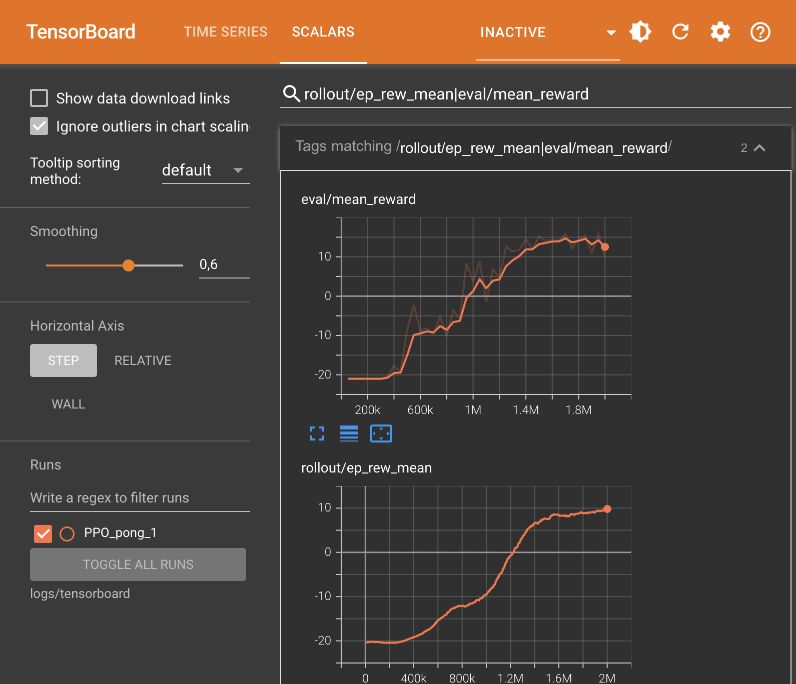

A curva superior mostra a recompensa média na avaliação periódica; a inferior mostra a média dos episódios de treinamento. Linhas escuras são os valores brutos e linhas destacadas usam suavização de 0,6.


In [ ]:
import subprocess
if 'tb_process' not in globals() or tb_process.poll() is not None:
    tb_log_handle=open(ROOT/'logs/tensorboard_server.log','a')
    tb_process=subprocess.Popen([sys.executable,'-m','tensorboard.main',
        '--logdir',str(ROOT/'logs/tensorboard'),'--host','127.0.0.1','--port','6006'],
        stdout=tb_log_handle,stderr=subprocess.STDOUT)
print('TensorBoard: http://127.0.0.1:6006')


## 9. Avaliação final e vídeo do agente treinado
Usamos o melhor checkpoint periódico, sem escolher manualmente uma partida favorável. O vídeo é uma partida com seed fixo.
O retorno de uma única gravação não substitui a média de avaliação. O número de parâmetros é recalculado do modelo realmente carregado.

### Resultado final

O melhor checkpoint periódico obteve retorno médio de **+13,6**, desvio-padrão **3,2**, em dez partidas de avaliação com seeds distintos dos periódicos. Os retornos foram **19, 15, 17, 11, 16, 10, 14, 12, 14 e 8**: **10 vitórias em 10 partidas**, sem garantia de invencibilidade fora dessa amostra. O baseline aleatório obteve média **−20,4** em cinco partidas.

O vídeo treinado abaixo é uma partida separada com seed 2026: o agente venceu por **21 a 16** (retorno **+5**). Não confundir esse retorno de uma gravação com a média da avaliação final.


In [8]:
eval_env=make_vec(seed=20_000)
trained=PPO.load(ROOT/'models/best_model',env=eval_env,device='cpu')
try:
    returns,lengths=evaluate_policy(trained,eval_env,n_eval_episodes=10,
        deterministic=True,return_episode_rewards=True)
    final=dict(returns=returns,mean=float(np.mean(returns)),std=float(np.std(returns)),
               episodes=10,seed=20_000,parameters=sum(p.numel() for p in trained.policy.parameters()))
    (ROOT/'artifacts/final_evaluation.json').write_text(json.dumps(final,indent=2))
finally: eval_env.close()
print('Aleatório:',json.loads((ROOT/'artifacts/random_evaluation.json').read_text()))
print('Treinado:',final)
trained_video, trained_video_info=record_episode(trained,'treinado')
display(Video(str(trained_video),embed=True))


Aleatório: {'returns': [-21.0, -21.0, -20.0, -20.0, -20.0], 'lengths': [3558, 3796, 3535, 3689, 5295], 'mean': -20.4, 'std': 0.4898979485566356, 'episodes': 5, 'seed': 1000}
Treinado: {'returns': [19.0, 15.0, 17.0, 11.0, 16.0, 10.0, 14.0, 12.0, 14.0, 8.0], 'mean': 13.6, 'std': 3.1999999999999997, 'episodes': 10, 'seed': 20000, 'parameters': 1687719}


## 10. Jogada inteligente e jogada burra — item l

Vídeo analisado: `videos/treinado/20261106_202710/treinado.mp4`, exibido integralmente na seção 9. O agente é a **raquete verde à direita**. Os tempos abaixo correspondem ao vídeo a 60 fps, na velocidade normal.

| Classificação | Intervalo no vídeo (mm:ss) | Comportamento observado | Justificativa |
|---|---|---|---|
| Inteligente | **00:02–00:06** | A raquete verde ajusta sua posição vertical, intercepta a bola por volta de 00:05 e a devolve para o lado esquerdo. | O posicionamento permite defender a própria área e manter a troca de bola, em vez de deixar a bola ultrapassar a raquete. A classificação se baseia na defesa observada, sem atribuir intenção humana ao agente. |
| Burra | **00:26–00:28** | Por volta de 00:27 a bola passa acima da raquete verde. O adversário marca e o placar passa de 0–3 para 1–3. | O posicionamento final fica abaixo da trajetória da bola e resulta em um ponto sofrido. É uma falha local de controle; uma política com bom resultado médio ainda pode cometer erros. |

Os trechos foram conferidos em quadros extraídos do arquivo real. Marcar ou perder um ponto isoladamente não define inteligência: a análise relaciona o movimento da raquete, a trajetória visível da bola e sua consequência.


## 11. Conferência dos entregáveis — itens a a m

| Item do enunciado | Onde está no notebook | Evidência |
|---|---|---|
| a. Jogo escolhido | Seção 1 | Pong / ALE/Pong-v5 |
| b. Instalar e jogar pessoalmente | Seções 2 e 3 | Ambiente instalado, jogar.py, relato pessoal e registro da sessão |
| c. Descrição do ambiente | Seção 1 | Observação RGB e pré-processamento, com referência oficial |
| d. Ações e quantidade | Seções 1 e 3 | Tabela de seis ações e consulta ao ambiente instalado |
| e. Recompensas | Seção 1 | +1 ao marcar, −1 ao sofrer, 0 nos demais frames |
| f. Vídeo de política aleatória | Seção 5 | Vídeo incorporado na saída, sem treinamento |
| g. Print do TensorBoard | Seção 8 | Print final incorporado como attachment no próprio notebook |
| h. Parâmetros alterados frente à galinha | Seção 6 | Tabela com valores da base, valores usados e justificativas |
| i. Tempo até política minimamente inteligente | Seção 7 | Critério explícito, 550.000 passos e 24min42s |
| j. Parâmetros da rede neural | Seção 7 e saída da seção 6 | 1.687.719 parâmetros, contagem programática |
| k. Vídeo após treinamento | Seção 9 | Vídeo incorporado na saída e avaliação final |
| l. Jogada inteligente e burra | Seção 10 | Intervalos 00:02–00:06 e 00:26–00:28, com análise |
| m. Notebook com código e documentação | Este arquivo | Código executado, saídas preservadas e referências |

**Revisão antes de enviar:** preencher o nome do aluno no início. Os vídeos e o print estão incorporados ao `.ipynb`, para visualização sem executar novamente o treinamento. Os arquivos originais permanecem nas pastas `videos/` e `evidence/`.


In [9]:
checks={
 'Jogo escolhido e descrito': True,
 'Ações e recompensas documentadas': True,
 'Sessão humana registrada': (ROOT/'artifacts/sessao_humana.json').exists(),
 'Vídeo aleatório': (ROOT/'artifacts/aleatorio_video.json').exists(),
 'Treino executado e tempo medido': (ROOT/'artifacts/training_summary.json').exists(),
 'Quantidade de parâmetros medida': (ROOT/'artifacts/network.json').exists(),
 'Avaliação final': (ROOT/'artifacts/final_evaluation.json').exists(),
 'Vídeo treinado': (ROOT/'artifacts/treinado_video.json').exists(),
 'Print do TensorBoard': (ROOT/'evidence/tensorboard.png').exists(),
}
for item, ok in checks.items(): print(('OK' if ok else 'PENDENTE'), '—', item)
print('Relato pessoal e análise dos timestamps incluídos. Revisão restante: nome do aluno.')
(ROOT/'artifacts/checklist.json').write_text(json.dumps(checks,ensure_ascii=False,indent=2))


OK — Jogo escolhido e descrito
OK — Ações e recompensas documentadas
OK — Sessão humana registrada
OK — Vídeo aleatório
OK — Treino executado e tempo medido
OK — Quantidade de parâmetros medida
OK — Avaliação final
OK — Vídeo treinado
OK — Print do TensorBoard
Relato pessoal e análise dos timestamps incluídos. Revisão restante: nome do aluno.


319

## 12. Referências
- [Requisitos da AC](https://docs.google.com/document/d/1rRM9H1-KAUtVdBNzHf6zw3Ukkh3f3bMy/edit).
- [Notebook base Freeway](https://drive.google.com/file/d/10liyDw_oMNjvP2N9g0IFz6nhaKWtpZc5/view).
- [Lista ALE](https://ale.farama.org/environments/complete_list/) e [Pong](https://ale.farama.org/environments/pong/).
- [Stable Baselines 3](https://stable-baselines3.readthedocs.io/en/master/), [PPO](https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html), [wrappers Atari](https://stable-baselines3.readthedocs.io/en/master/common/atari_wrappers.html), [TensorBoard](https://stable-baselines3.readthedocs.io/en/master/guide/tensorboard.html).
- [Preset PPO Atari do RL Zoo](https://github.com/DLR-RM/rl-baselines3-zoo/blob/master/hyperparams/ppo.yml).

Consultadas em 06/11/2026. As versões efetivamente instaladas são registradas em `artifacts/versions.json`.
